In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
sns.set()

import warnings

pd.set_option('display.max_rows', None)  # Display all rows


# **Importing the dataset and inspecting the dataset**





In [2]:
data = pd.read_csv("Housing (1).csv")

In [3]:
data.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [4]:
data.shape

(545, 13)

In [5]:
data.describe()


,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [7]:
data.nunique().to_frame("Number of unique values")

,Number of unique values
price,219
area,284
bedrooms,6
bathrooms,4
stories,4
mainroad,2
guestroom,2
basement,2
hotwaterheating,2
airconditioning,2


# Splitting the features into numerical and categorical features

In [8]:
numericalData_columns = data.select_dtypes(include=np.number)
categoricalData_columns = data.select_dtypes(include="object")

print("NUMERICAL COLUMNS:",numericalData_columns.columns)

print("CATEGORICAL COLUMNS:",categoricalData_columns.columns)


NUMERICAL COLUMNS: Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'parking'], dtype='object')
CATEGORICAL COLUMNS: Index(['mainroad', 'guestroom', 'basement', 'hotwaterheating',
       'airconditioning', 'prefarea', 'furnishingstatus'],
      dtype='object')


# Unique features of categorical features

In [9]:
for i in categoricalData_columns:
  print(data[i].value_counts())
  print("-----------------------------------------------")

mainroad
yes    468
no      77
Name: count, dtype: int64
-----------------------------------------------
guestroom
no     448
yes     97
Name: count, dtype: int64
-----------------------------------------------
basement
no     354
yes    191
Name: count, dtype: int64
-----------------------------------------------
hotwaterheating
no     520
yes     25
Name: count, dtype: int64
-----------------------------------------------
airconditioning
no     373
yes    172
Name: count, dtype: int64
-----------------------------------------------
prefarea
no     417
yes    128
Name: count, dtype: int64
-----------------------------------------------
furnishingstatus
semi-furnished    227
unfurnished       178
furnished         140
Name: count, dtype: int64
-----------------------------------------------


Here the feature "Utilities" has only one unique value so we drop this feature and update the "categoricalData_columns"

# Detecting Duplicates

In [10]:
data.duplicated().sum()

np.int64(0)

# Detecting Missing Values

In [11]:
data.isnull().sum()

,0
price,0
area,0
bedrooms,0
bathrooms,0
stories,0
mainroad,0
guestroom,0
basement,0
hotwaterheating,0
airconditioning,0


# **Exploratory Data Analysis**

## Detecting Outliers of the Price and Area



<Axes: ylabel='price'>

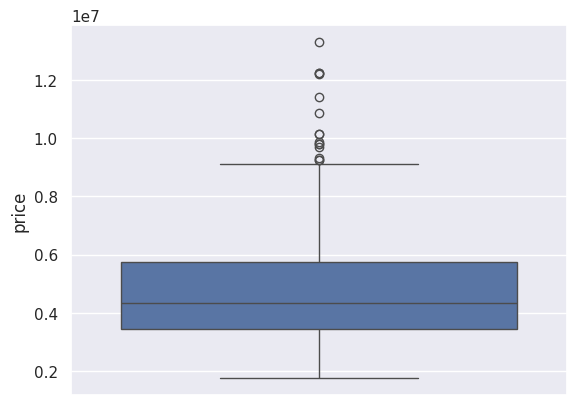

In [12]:
sns.boxplot(data["price"])

<Axes: ylabel='area'>

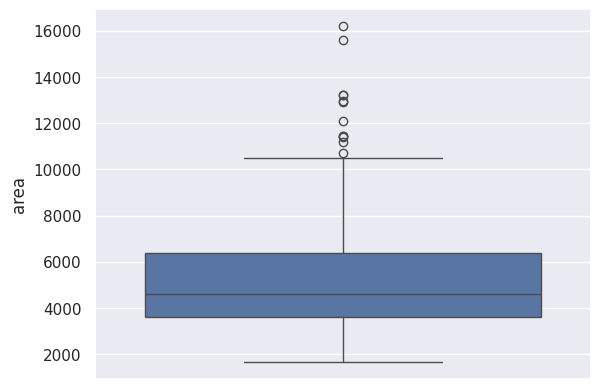

In [19]:
sns.boxplot(data['area'])

<Axes: xlabel='furnishingstatus', ylabel='count'>

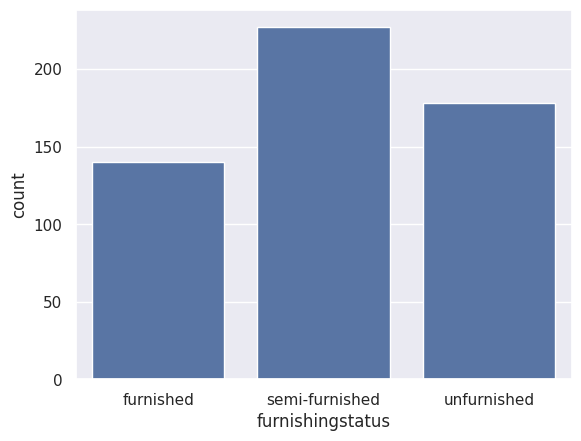

In [13]:
sns.countplot(x='furnishingstatus', data=data)

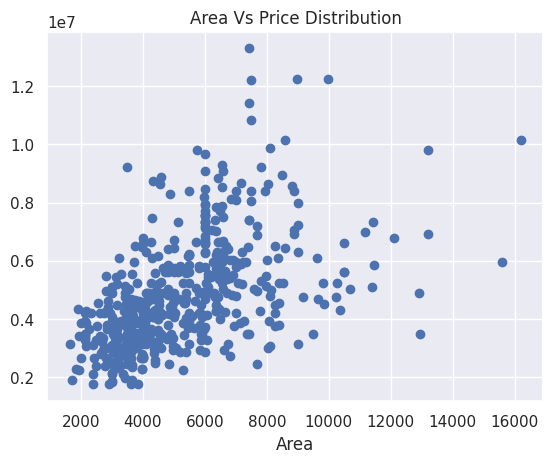

In [14]:
plt.scatter(x='area', y='price', data=data)
plt.title("Area Vs Price Distribution")
plt.xlabel("Area")
plt.show()


<Axes: xlabel='price', ylabel='Count'>

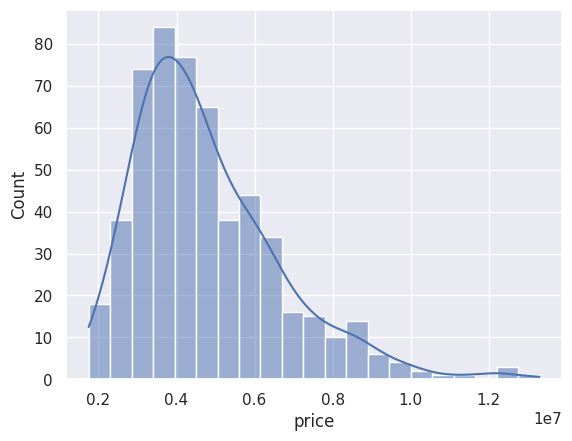

In [15]:
sns.histplot(data["price"], kde= True)

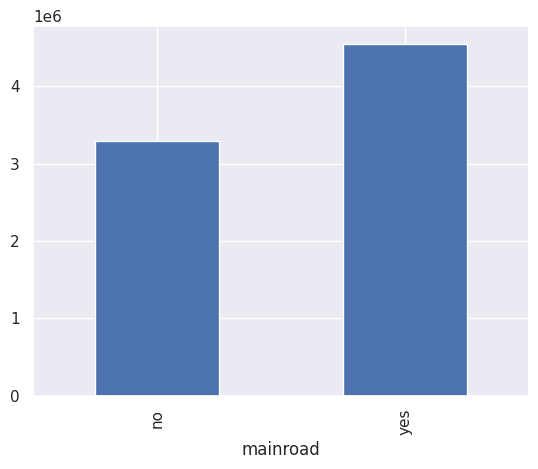

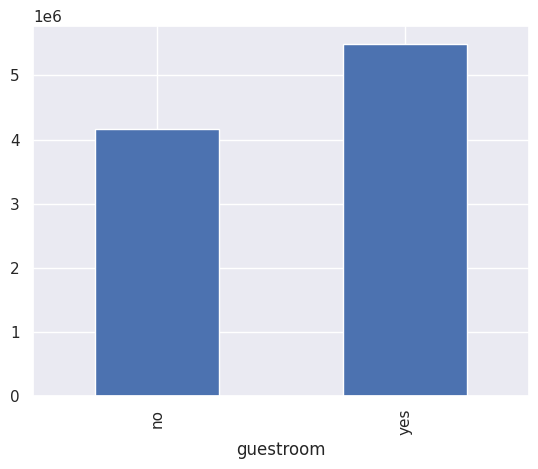

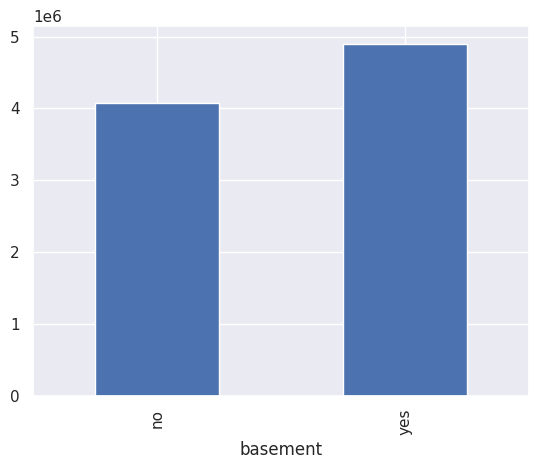

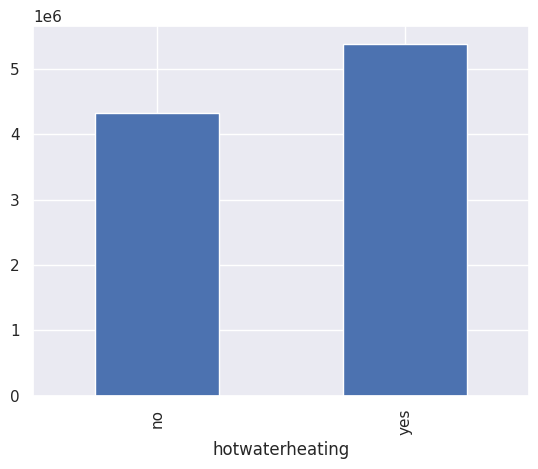

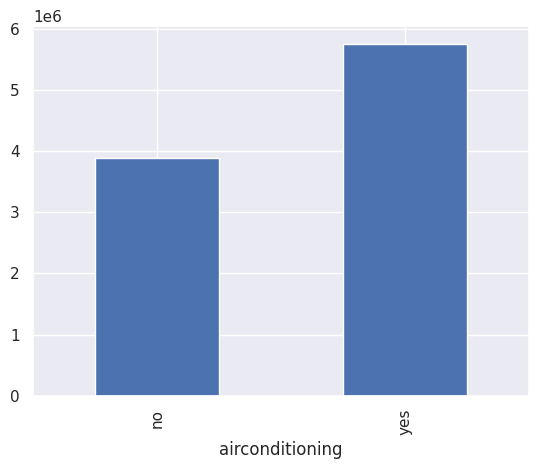

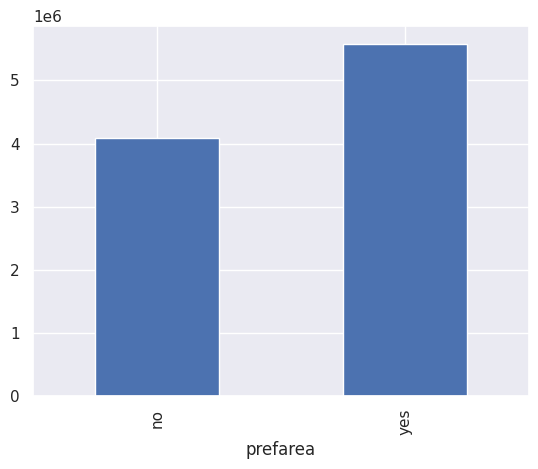

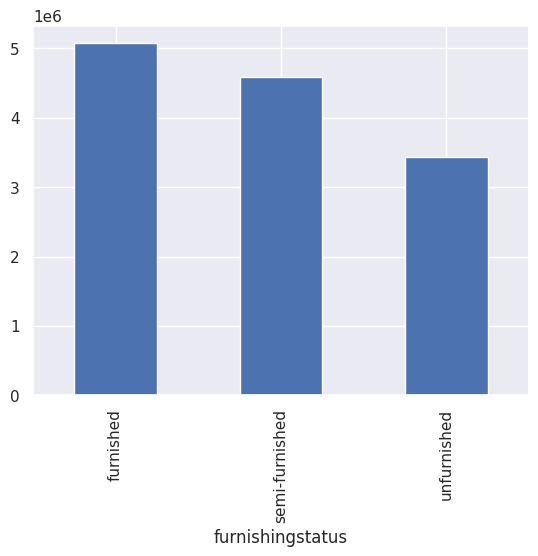

In [16]:
for feature in categoricalData_columns:
  data.groupby(feature)["price"].median().plot.bar()
  plt.show()

# Correlation Analysis

<Axes: >

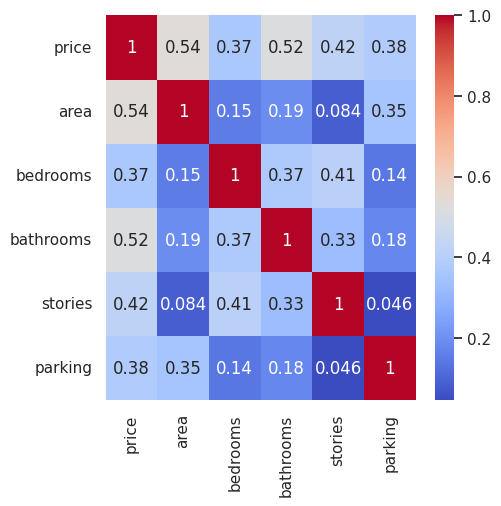

In [18]:
plt.figure(figsize=(5,5))
sns.heatmap(numericalData_columns.corr(), annot = True, cmap="coolwarm")

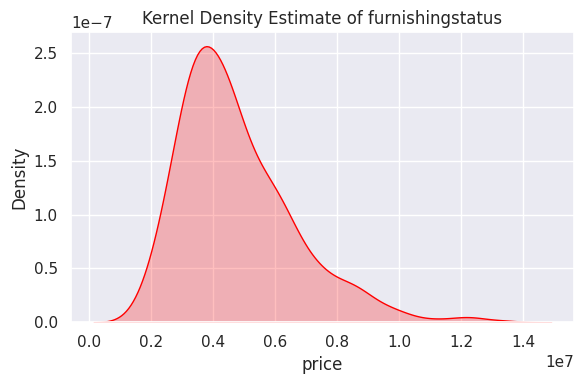

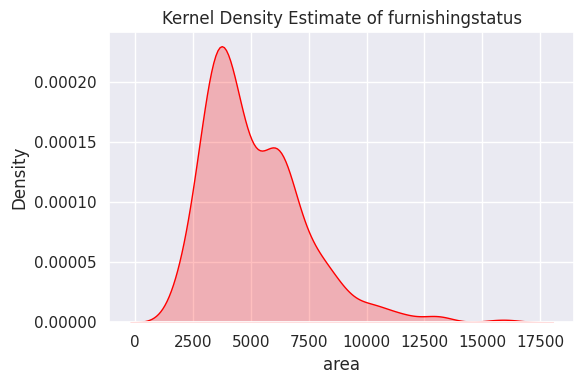

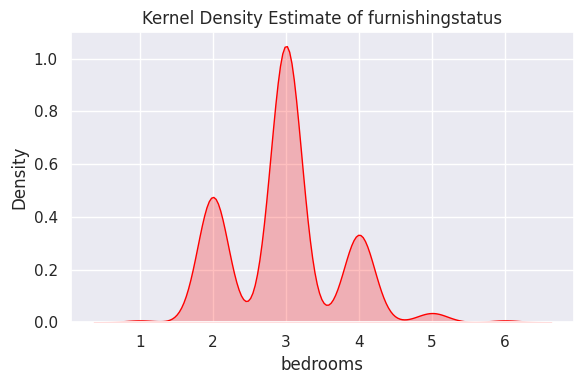

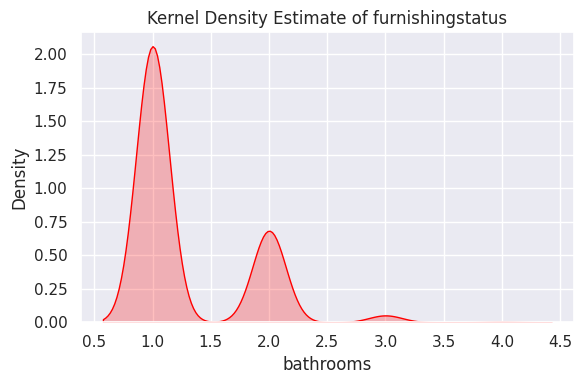

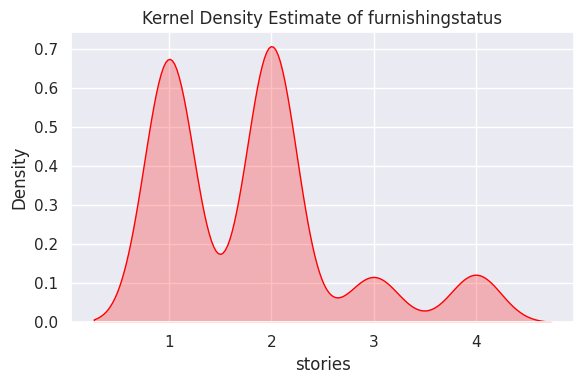

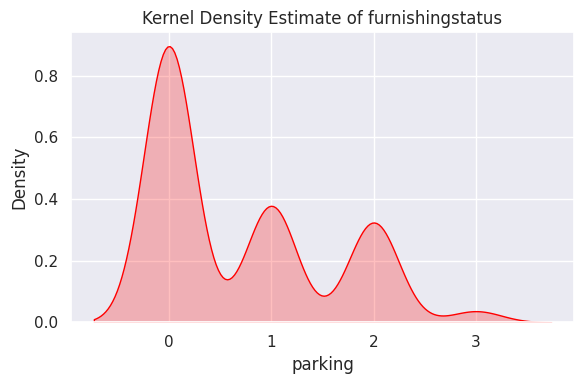

In [32]:
for feature in numericalData_columns:
    plt.figure(figsize=(6, 4))  # Adjust the figure size
    sns.kdeplot(data[feature], color="red", fill=True)  # Use KDE plot
    plt.title(f"Kernel Density Estimate of {i}")
    plt.xlabel(f"{feature}")
    plt.ylabel("Density")
    plt.tight_layout()
    plt.show()


## Label Encoding

In [12]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

encoding_mapping = {}

for feature in categoricalData_columns:
   data[feature] = le.fit_transform(data[feature])
   encoding_mapping[feature] = dict(zip(le.classes_, le.transform(le.classes_)))
   print(f"Mapping for {feature}: {encoding_mapping[feature]}")


Mapping for mainroad: {'no': np.int64(0), 'yes': np.int64(1)}
Mapping for guestroom: {'no': np.int64(0), 'yes': np.int64(1)}
Mapping for basement: {'no': np.int64(0), 'yes': np.int64(1)}
Mapping for hotwaterheating: {'no': np.int64(0), 'yes': np.int64(1)}
Mapping for airconditioning: {'no': np.int64(0), 'yes': np.int64(1)}
Mapping for prefarea: {'no': np.int64(0), 'yes': np.int64(1)}
Mapping for furnishingstatus: {'furnished': np.int64(0), 'semi-furnished': np.int64(1), 'unfurnished': np.int64(2)}


In [13]:
data.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,0


# **Outlier Handling for Price and Area**

In [14]:
Q1 = data['price'].quantile(0.25)
Q3 = data['price'].quantile(0.75)
IQR = Q3 - Q1

lower_price = Q1 - 1.5 * IQR
upper_price = Q3 + 1.5 * IQR

print("Lower bound:", lower_price)
print("Upper bound:", upper_price)
print("Min price:", data['price'].min())
print("Max price:", data['price'].max())


Lower bound: -35000.0
Upper bound: 9205000.0
Min price: 1750000
Max price: 13300000


In [15]:
Q1 = data['area'].quantile(0.25)
Q3 = data['area'].quantile(0.75)

IQR = Q3 - Q1
lower_area = Q1 - 1.5 * IQR
upper_area = Q3 + 1.5 * IQR


print("Lower bound:", lower_area)
print("Upper bound:", upper_area)
print("Min price:", data['area'].min())
print("Max price:", data['area'].max())

Lower bound: -540.0
Upper bound: 10500.0
Min price: 1650
Max price: 16200


In [16]:
# Keep only rows within both bounds for price and area

original_shape = data.shape
data_clean = data[
    (data['price'] >= lower_price) & (data['price'] <= upper_price) &
    (data['area'] >= lower_area) & (data['area'] <= upper_area)
]

print("Original shape:", original_shape)
print("After removing outliers:", data_clean.shape)
print("Rows dropped:", original_shape[0] - data_clean.shape[0])

Original shape: (545, 13)
After removing outliers: (520, 13)
Rows dropped: 25


#**Building the Model**

In [17]:
X = data_clean.iloc[:,1:]
y = data_clean.iloc[:,0]

In [19]:
from sklearn.model_selection import train_test_split

X_train,X_test, y_train, y_test = train_test_split(X,y, test_size = 0.3, random_state=42)

In [20]:
print(X_train.shape,X_test.shape,y_train.shape,y_test.shape)

(364, 12) (156, 12) (364,) (156,)


# **Linear Regression**

In [21]:
from sklearn.linear_model import LinearRegression

regressor = LinearRegression()
regressor.fit(X_train,y_train)

LinearRegression()

In [22]:
y_pred = regressor.predict(X_test)
y_pred


array([4681707.63799401, 4791591.81082261, 6406776.69387937,
       3287532.23336304, 6453448.02159192, 2939177.94134202,
       3453860.23455539, 4609209.28641151, 4595386.06717045,
       2927758.06488329, 4504905.69238275, 4034401.7262969 ,
       6118605.8116598 , 3112721.8773291 , 7507625.3646123 ,
       4008204.06209651, 3811524.80534332, 6014020.17307228,
       3607299.61835488, 4564810.92330537, 5645435.40172017,
       6691830.86613649, 5063996.04587179, 5842872.04129932,
       3334127.64540652, 4776155.01755129, 6488146.17879413,
       3244717.90128887, 4253108.87715271, 5331238.17079434,
       4133760.43349725, 3980676.5766234 , 4302277.74555678,
       6818206.02404304, 4123425.69709926, 3839430.52058632,
       3717506.8265022 , 4998681.55948992, 4643278.47904892,
       3773129.94312512, 4160395.46843969, 3745334.38879379,
       4974382.86802651, 3393190.42622689, 3450656.99702622,
       4553643.33317213, 3614326.13602326, 3867836.57456659,
       4777926.57636816,

In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mse,2))
print("MSE:", round(mae,2))
print("R2 score:", round(r2,2))




MAE: 939885345776.62
MSE: 740440.56
R2 score: 0.7


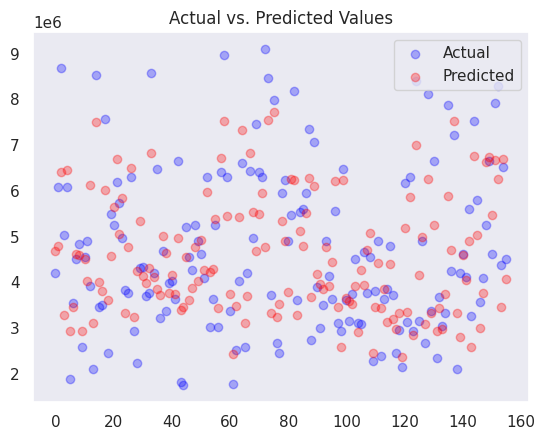

In [26]:
plt.scatter(range(len(y_test)), y_test, c='blue', label='Actual', alpha=0.3)
plt.scatter(range(len(y_pred)), y_pred, c='red', label='Predicted', alpha=0.3)
plt.title("Actual vs. Predicted Values")
plt.legend()
plt.grid()
plt.show()

#**Random Forest Regression**

In [27]:
from sklearn.ensemble import RandomForestRegressor

rfr = RandomForestRegressor(random_state=42)
rfr.fit(X_train, y_train)


RandomForestRegressor(random_state=42)

In [28]:
y_pred1 = rfr.predict(X_test)
y_pred1


array([4300450.        , 4074175.        , 6796084.4       ,
       3994550.        , 6502405.        , 3405640.        ,
       3323040.        , 5388110.        , 5229000.        ,
       2257010.        , 4361735.        , 3826550.        ,
       5755680.        , 2878750.        , 7836459.4       ,
       4482310.        , 2582860.        , 6577830.        ,
       3603040.        , 4189570.        , 5499480.        ,
       6803189.4       , 5720085.        , 4417910.        ,
       2776480.        , 4447030.        , 6418300.        ,
       3484775.        , 5131560.        , 5240970.        ,
       4098535.        , 3642100.        , 4197970.        ,
       7363332.2       , 3339980.        , 4286835.        ,
       2973460.        , 5364590.        , 3359160.        ,
       3380580.        , 4127760.        , 3904215.        ,
       6088810.        , 3794140.        , 3129630.        ,
       3899980.        , 4008550.        , 3574550.        ,
       3445050.        ,

In [30]:
mae = mean_absolute_error(y_test, y_pred1)
mse = mean_squared_error(y_test, y_pred1)
r2 = r2_score(y_test, y_pred1)

print("MAE:", round(mse,2))
print("MSE:", round(mae,2))
print("R2 score:", round(r2,2))

MAE: 1090730823374.97
MSE: 775584.21
R2 score: 0.65


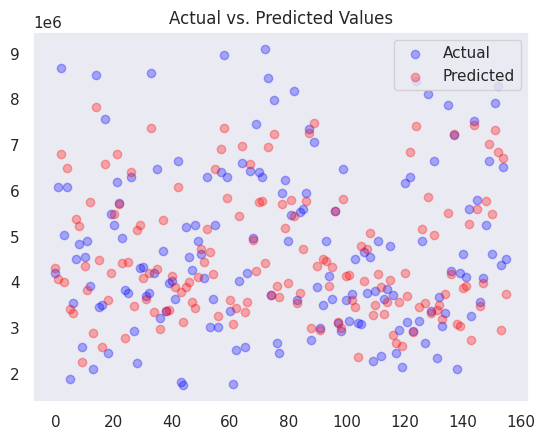

In [31]:
plt.scatter(range(len(y_test)), y_test, c='blue', label='Actual', alpha=0.3)
plt.scatter(range(len(y_pred1)), y_pred1, c='red', label='Predicted', alpha=0.3)
plt.title("Actual vs. Predicted Values")
plt.legend()
plt.grid()
plt.show()

# **Decision Tree Regressor**

In [32]:
from sklearn.tree import DecisionTreeRegressor

reg = DecisionTreeRegressor(max_depth=10)
reg.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=10)

In [33]:
y_pred2 = reg.predict(X_test)
y_pred2

array([4083100.        , 3939444.44444444, 5740000.        ,
       4620000.        , 7140000.        , 3500000.        ,
       3154500.        , 5600000.        , 6090000.        ,
       2380000.        , 4007500.        , 4083100.        ,
       6020000.        , 2347000.        , 7035000.        ,
       4550000.        , 2380000.        , 6580000.        ,
       3222450.        , 4083100.        , 4477666.66666667,
       6650000.        , 5810000.        , 3570000.        ,
       2380000.        , 4083100.        , 5906250.        ,
       3222450.        , 5600000.        , 5236000.        ,
       4767000.        , 3500000.        , 4083100.        ,
       6930000.        , 4830000.        , 4418750.        ,
       2653000.        , 6860000.        , 3500000.        ,
       2800000.        , 4083100.        , 4469500.        ,
       8750000.        , 3395000.        , 3154500.        ,
       3885000.        , 4469500.        , 3344000.        ,
       2800000.        ,

In [34]:
mae = mean_absolute_error(y_test, y_pred2)
mse = mean_squared_error(y_test, y_pred2)
r2 = r2_score(y_test, y_pred2)

print("MAE:", round(mse,2))
print("MSE:", round(mae,2))
print("R2 score:", round(r2,2))

MAE: 1608189944968.8
MSE: 951555.02
R2 score: 0.49


# **Neural Netoworks : Multilayer Perceptron with GridSearchCV**

In [35]:
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import GridSearchCV

In [36]:

model = MLPRegressor(hidden_layer_sizes=(100,), activation='relu', solver='adam',max_iter=20)

param_grid = {
    'batch_size': [16, 32],
    'learning_rate_init': [0.001, 0.01]
}


In [37]:
grid_search = GridSearchCV(estimator= model, param_grid=param_grid, cv=3)
grid_search.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py

GridSearchCV(cv=3, estimator=MLPRegressor(max_iter=20),
             param_grid={'batch_size': [16, 32],
                         'learning_rate_init': [0.001, 0.01]})

In [38]:
best_model = grid_search.best_estimator_
best_model

MLPRegressor(batch_size=16, learning_rate_init=0.01, max_iter=20)

In [39]:
y_pred3 = best_model.predict(X_test)
y_pred3

array([6036078.68212443, 3713841.98162112, 6174342.71117128,
       3055470.72253964, 5708390.43359424, 3149252.78567034,
       3324997.39496516, 8496711.5025098 , 5210516.9529831 ,
       3107066.10433663, 3142704.98373248, 4658843.07710954,
       6262822.51838868, 2075903.4166489 , 5645980.36717571,
       4589688.7343301 , 3112822.64850761, 5177445.66932152,
       4175656.17443447, 6879841.80204469, 7344866.65540885,
       5478801.89192597, 4315499.53794043, 3811197.90560321,
       2893808.46291482, 7111408.86324375, 5695830.79064743,
       4277961.74951731, 4572630.6152869 , 8928000.08046435,
       3023864.16056232, 2695660.96111711, 5975120.43789789,
       7587935.60353915, 1859153.24964029, 3419801.76862674,
       2320294.68692032, 5174423.19108278, 3026645.05400489,
       3417209.27293253, 4659444.55615308, 3083317.63140718,
       3488658.68052266, 2593205.57593712, 3324284.80305477,
       2749271.13435302, 3039194.86021658, 5481515.17695615,
       3284923.8772431 ,

In [40]:
mae = mean_absolute_error(y_test, y_pred3)
mse = mean_squared_error(y_test, y_pred3)
r2 = r2_score(y_test, y_pred3)

print("MAE:", round(mse,2))
print("MSE:", round(mae,2))
print("R2 score:", round(r2,2))

MAE: 2607679376444.31
MSE: 1260265.1
R2 score: 0.17


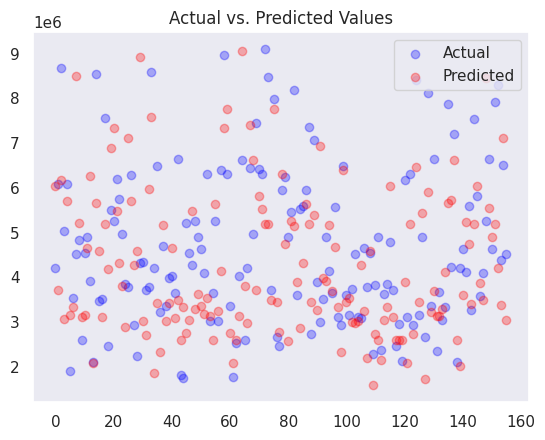

In [41]:
plt.scatter(range(len(y_test)), y_test, c='blue', label='Actual', alpha=0.3)
plt.scatter(range(len(y_pred3)), y_pred3, c='red', label='Predicted', alpha=0.3)
plt.title("Actual vs. Predicted Values")
plt.legend()
plt.grid()
plt.show()

# **Gradient Boosting**

In [42]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(loss='squared_error',
                                learning_rate=0.1,
                                n_estimators=300,
                                max_depth = 1
                              )

In [43]:
gbr.fit(X_train,y_train)

GradientBoostingRegressor(max_depth=1, n_estimators=300)

In [44]:
y_pred4 = gbr.predict(X_test)
y_pred4

array([4651971.35960119, 4623228.56826681, 6405268.2819778 ,
       3271364.48168147, 6361630.71025857, 3035968.64083657,
       3773465.90341804, 4075194.37597658, 5281783.65841507,
       2752905.95944783, 4155247.4951571 , 4057227.16813249,
       5842941.91719839, 2941457.39066396, 7118001.64879628,
       4272175.38301818, 3692259.27344667, 6293582.55776949,
       3435674.31539397, 4840433.57903806, 5204461.2845544 ,
       6593108.12143088, 5249788.72013468, 5033352.54439736,
       3012557.78085318, 4532513.02114898, 6436848.51908362,
       3435674.31539397, 4576461.19406071, 4717995.02566545,
       3697969.59620048, 3744022.2307653 , 4498875.00996668,
       6730818.36496121, 4112249.7937831 , 4261678.23016024,
       3756188.29783017, 5333462.94616713, 4098534.57216444,
       3630820.66295369, 4309494.30722287, 3564587.02086567,
       4852390.54144351, 3293245.78276268, 3359437.37551221,
       4399286.38145698, 3815808.89156336, 4076235.48583518,
       4712293.04609855,

In [45]:
mae = mean_absolute_error(y_test, y_pred4)
mse = mean_squared_error(y_test, y_pred4)
r2 = r2_score(y_test, y_pred4)

print("MAE:", round(mse,2))
print("MSE:", round(mae,2))
print("R2 score:", round(r2,2))

MAE: 956165883777.61
MSE: 741836.3
R2 score: 0.69


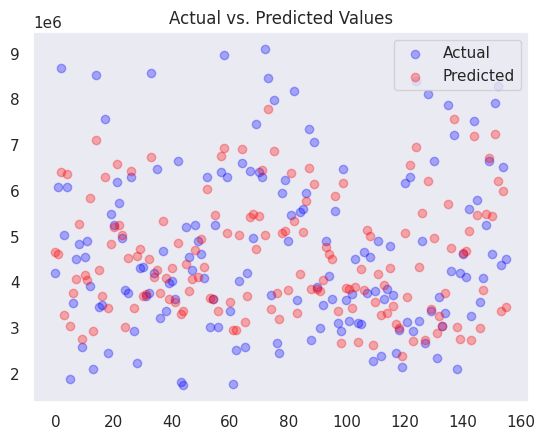

In [46]:
plt.scatter(range(len(y_test)), y_test, c='blue', label='Actual', alpha=0.3)
plt.scatter(range(len(y_pred4)), y_pred4, c='red', label='Predicted', alpha=0.3)
plt.title("Actual vs. Predicted Values")
plt.legend()
plt.grid()
plt.show()

# **New Prediction using Linear Regression**


In [48]:
X_new = [[7420, 4, 2, 3, 2, 1, 0, 1, 0, 1, 1, 2]]
y_pred = regressor.predict(X_new)
print("Predicted Price:", y_pred[0])


Predicted Price: 7799897.863492219


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
